In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as spc

from libOctopusIO import store_transition_dipole, load_kpoints_data, extract_info
from libElectrical import get_conductivity, get_permittivity, \
                          plot_conductivity, load_epsilon_table

In [2]:
main_path = "./Mo/"

---
### Conductivity

In [3]:
Eh_to_eV = spc.physical_constants["hartree-electron volt relationship"][0]

In [4]:
small_delta = 0.4
large_delta = 0.8
n_decimals = 4
negative_contributions = True

In [5]:
k_main_path = os.path.join(main_path, "16x16x16")

kpoints_data = load_kpoints_data(output_path=k_main_path)
info_path = os.path.join(k_main_path, "static", "info")
band_path = os.path.join(k_main_path, "static", "bandstructure")
info_data = extract_info(info_path, band_path)

omega_16_small, conductivity_16_small = get_conductivity(kpoints_data, info_data, mode="KuboGreenwood", damping_parameter=small_delta/Eh_to_eV, round_to_decimals=n_decimals, negative_contributions=negative_contributions)

Text(0.5, 1.0, '$\\delta$ = 0.4 eV')

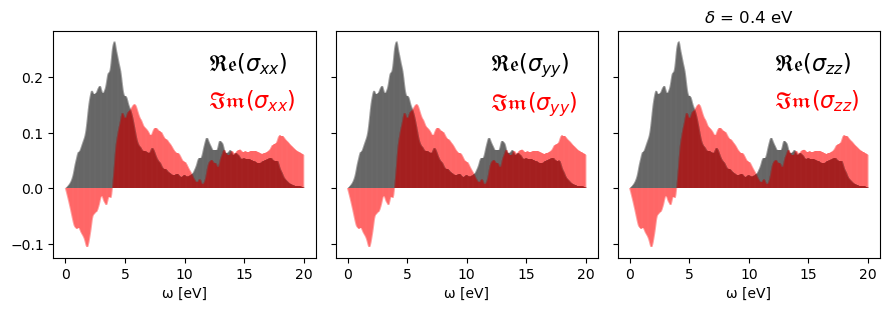

In [6]:
plot_conductivity(omega_16_small, conductivity_16_small, 20, diagonal_only=True, stem_alpha=0.01)
plt.title(f"$\delta$ = {small_delta} eV")

---
### Permittivity

In [7]:
epsilon_16_small = get_permittivity(omega_16_small, conductivity_16_small)
#epsilon_16_large = get_permittivity(omega_16_large, conductivity_16_large)

/home/aibertoni/vault/main/Academia/Thibault/dipolar_matrix_elements/libElectrical.py:182: RuntimeWarning: invalid value encountered in true_divide
  epsilon = 1 + 1j * (conductivity/omega) * (4*np.pi)


In [8]:
exp_datafile = "Mo-Palik"
exp_datapath = os.path.join(main_path, exp_datafile)
energy_exp, epsilon_exp = load_epsilon_table(exp_datapath)

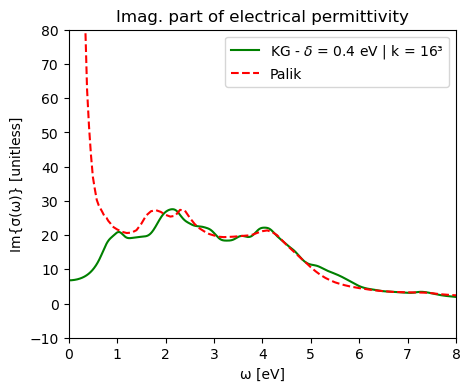

In [9]:
plt.figure(figsize=(5,4))

plt.plot(omega_16_small*Eh_to_eV, np.imag(epsilon_16_small), color="green", label=f"KG - $\delta$ = {small_delta} eV | k = 16³")
#plt.plot(omega_16_large*Eh_to_eV, np.imag(epsilon_16_large), color="green", ls="dotted", label=f"KG - $\delta$ = {large_delta} eV | k = 16³")
plt.plot(energy_exp, np.imag(epsilon_exp), color="red", ls="dashed", label="Palik")

plt.xlim(0,8)
plt.ylim(-10,80)
plt.title("Imag. part of electrical permittivity")
plt.xlabel("ω [eV]")
plt.ylabel("Im{σ(ω)} [unitless]")
plt.legend(bbox_to_anchor=(1,1))

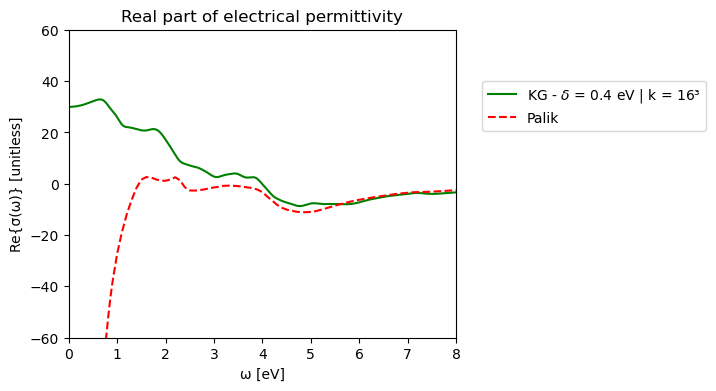

In [11]:
plt.figure(figsize=(5,4))

plt.plot(omega_16_small*Eh_to_eV, np.real(epsilon_16_small), color="green", label=f"KG - $\delta$ = {small_delta} eV | k = 16³")
#plt.plot(omega_16_large*Eh_to_eV, np.real(epsilon_16_large), color="green", ls="dotted", label=f"KG - $\delta$ = {large_delta} eV | k = 16³")
plt.plot(energy_exp, np.real(epsilon_exp), color="red", ls="dashed", label="Palik")

plt.xlim(0,8)
plt.ylim(-60,60)
plt.title("Real part of electrical permittivity")
plt.xlabel("ω [eV]")
plt.ylabel("Re{σ(ω)} [unitless]")
plt.legend(bbox_to_anchor=(1.05,0.65))

---

**Notebook by: Andrés Ignacio Bertoni 
(andresibertoni@gmail.com)**